In [1]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

In [3]:
data = df.select_dtypes(include=['int64', 'float64'])

In [4]:
data = data.loc[:, data.nunique() > 1]

In [5]:
data = data.fillna(data.mean())

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(data)

In [7]:
wcss = []

In [8]:
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

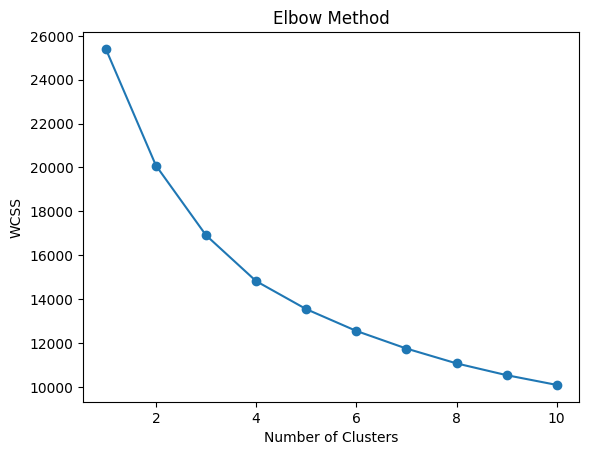

In [9]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X)

In [11]:
print(df[['Cluster']].head(10))
print("\nCluster Counts:")
print(df['Cluster'].value_counts())

   Cluster
0        1
1        2
2        1
3        1
4        1
5        1
6        1
7        1
8        1
9        0

Cluster Counts:
Cluster
1    1183
2     906
0     734
Name: count, dtype: int64


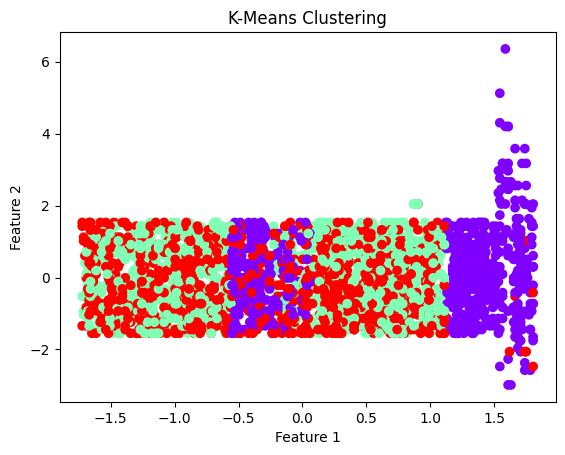

In [12]:
plt.scatter(X[:, 0], X[:, 1], c=df['Cluster'], cmap='rainbow')
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clustering")
plt.show()